In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

import os
FIGDIR = "results/eda_visualizations"
os.makedirs(FIGDIR, exist_ok=True)

GLU = pd.read_csv("results/outputs/diabetes_glucose.csv")
print("loaded:", GLU.shape)
GLU.head()

loaded: (13511, 31)


,patient_id,timestamp,date,time,hour,time_of_day,day_of_week,is_weekend,reading_index,code,context,code_description,glucose_mg_dl,prev_glucose,prev_glucose_2,glucose_change,hours_since_prev,hours_to_next,rolling_mean_3,rolling_std_3,insulin_regular_6h,insulin_nph_6h,insulin_ultralente_6h,total_insulin_6h,daily_total_insulin,meals_6h,exercise_6h,hypo_symptoms_6h,risk_class,next_glucose,next_risk_class
0,1,1991-04-21 09:09:00,1991-04-21,09:09,9,morning,Sunday,True,1,58,pre_breakfast,Pre-breakfast blood glucose,100.0,NaN,NaN,NaN,NaN,7.983333,100.000000,NaN,9.0,13.0,0.0,22.0,29.0,0,0,0,Normal,119.0,Normal
1,1,1991-04-21 17:08:00,1991-04-21,17:08,17,afternoon,Sunday,True,2,62,pre_supper,Pre-supper blood glucose,119.0,100.0,NaN,19.0,7.983333,5.716667,109.500000,13.435029,7.0,0.0,0.0,7.0,29.0,0,0,0,Normal,123.0,Normal
2,1,1991-04-21 22:51:00,1991-04-21,22:51,22,night_late,Sunday,True,3,48,unspecified,Unspecified blood glucose measurement,123.0,119.0,100.0,4.0,5.716667,8.733333,114.000000,12.288206,7.0,0.0,0.0,7.0,29.0,0,0,0,Normal,216.0,Hyperglycemic
3,1,1991-04-22 07:35:00,1991-04-22,07:35,7,morning,Monday,False,4,58,pre_breakfast,Pre-breakfast blood glucose,216.0,123.0,119.0,93.0,8.733333,9.350000,152.666667,54.884728,10.0,13.0,0.0,23.0,32.0,0,0,0,Hyperglycemic,211.0,Hyperglycemic
4,1,1991-04-22 16:56:00,1991-04-22,16:56,16,afternoon,Monday,False,5,62,pre_supper,Pre-supper blood glucose,211.0,216.0,123.0,-5.0,9.350000,14.483333,183.333333,52.309974,9.0,0.0,0.0,9.0,32.0,0,0,0,Hyperglycemic,257.0,Hyperglycemic


In [2]:
missing = GLU.isna().sum()
missing_pct = (missing / len(GLU) * 100).round(2)
pd.DataFrame({"n_missing": missing, "pct": missing_pct})[missing > 0]\
    .sort_values("n_missing", ascending=False)

,n_missing,pct
prev_glucose_2,140,1.04
prev_glucose,70,0.52
glucose_change,70,0.52
hours_since_prev,70,0.52
hours_to_next,70,0.52
rolling_std_3,70,0.52
next_glucose,70,0.52
next_risk_class,70,0.52


In [3]:
first = GLU[GLU.reading_index == 1]
print("patients:", GLU.patient_id.nunique())
print("rows with reading_index == 1:", len(first))
print("of those, prev_glucose is null:", first.prev_glucose.isna().sum())
print()
print("rows where prev_glucose_2 is null:", GLU.prev_glucose_2.isna().sum())
print("rows with reading_index <= 2: ", (GLU.reading_index <= 2).sum())

patients: 70
rows with reading_index == 1: 70
of those, prev_glucose is null: 70

rows where prev_glucose_2 is null: 140
rows with reading_index <= 2:  140


In [4]:
ALL = pd.read_csv("results/outputs/diabetes_all_records.csv")
ALL[ALL.raw_value.astype(str).str.contains("Hi|Lo", na=False)][
    ["patient_id", "raw_date", "raw_code", "raw_value", "issue"]]

,patient_id,raw_date,raw_code,raw_value,issue
1112,2,10-31-1989,60,0Hi,glucose_out_of_range
1146,2,11-04-1989,62,0Hi,glucose_out_of_range
1152,2,11-05-1989,60,0Hi,glucose_out_of_range
1160,2,11-06-1989,60,0Hi,glucose_out_of_range
1164,2,11-06-1989,48,0Hi,glucose_out_of_range
1178,2,11-08-1989,62,0Lo,glucose_out_of_range
1554,2,12-25-1989,48,0Hi,glucose_out_of_range


In [5]:
GLU_clean = GLU.dropna(subset=["prev_glucose", "next_glucose"])\
               .drop(columns=["prev_glucose_2"]).copy()

print("rows before:", len(GLU))
print("rows after: ", len(GLU_clean))
print("dropped:    ", len(GLU) - len(GLU_clean),
      f"({(len(GLU)-len(GLU_clean))/len(GLU)*100:.2f}%)")
print("nulls remaining:", GLU_clean.isna().sum().sum())

rows before: 13511
rows after:  13371
dropped:     140 (1.04%)
nulls remaining: 0


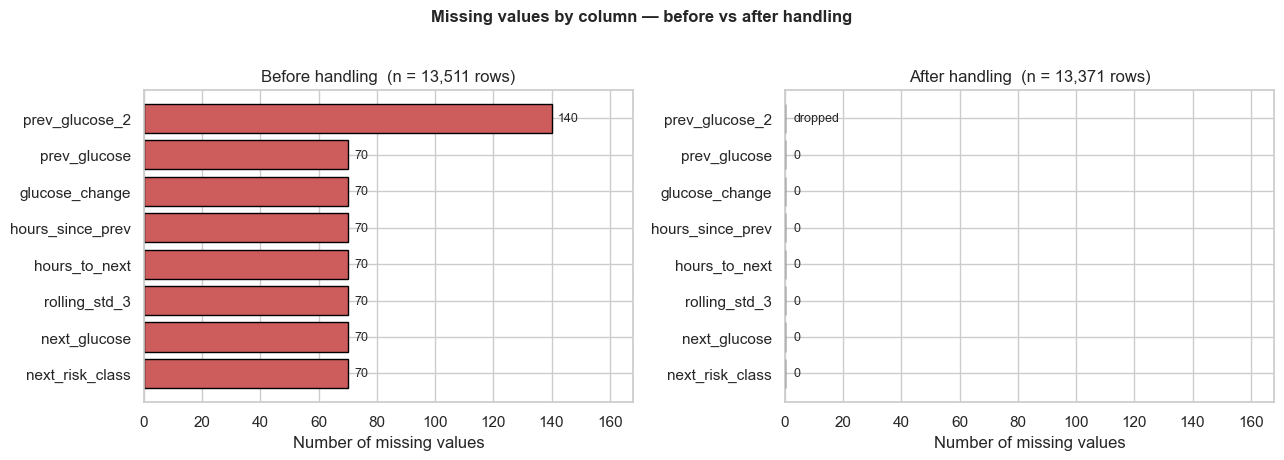

In [6]:
miss_before = GLU.isna().sum()
miss_before = miss_before[miss_before > 0].sort_values(ascending=False)
cols = list(miss_before.index)

after_counts, after_labels = [], []
for c in cols:
    if c in GLU_clean.columns:
        n = int(GLU_clean[c].isna().sum())
        after_counts.append(n)
        after_labels.append(str(n))
    else:
        after_counts.append(0)
        after_labels.append("dropped")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bars0 = axes[0].barh(cols, miss_before.values, color="indianred", edgecolor="black")
for b, v in zip(bars0, miss_before.values):
    axes[0].text(v + miss_before.max()*0.015, b.get_y() + b.get_height()/2, str(int(v)), va="center", fontsize=9)
axes[0].set_xlabel("Number of missing values")
axes[0].set_title(f"Before handling  (n = {len(GLU):,} rows)")
axes[0].set_xlim(0, miss_before.max() * 1.2)
axes[0].invert_yaxis()

bars1 = axes[1].barh(cols, after_counts, color="seagreen", edgecolor="black")
for b, lbl in zip(bars1, after_labels):
    axes[1].text(miss_before.max()*0.02, b.get_y() + b.get_height()/2, lbl, va="center", fontsize=9)
axes[1].set_xlabel("Number of missing values")
axes[1].set_title(f"After handling  (n = {len(GLU_clean):,} rows)")
axes[1].set_xlim(0, miss_before.max() * 1.2)
axes[1].invert_yaxis()

fig.suptitle("Missing values by column — before vs after handling", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{FIGDIR}/missing_values_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation what was affected after handling missing values

The chart confirms the fix: all 8 affected columns go from non-zero missing counts (up to 140 for `prev_glucose_2`) to **zero** after cleaning. The redundant `prev_glucose_2` column is dropped outright rather than shown as "0", since the column itself is removed. Row count falls from 13,511 → 13,371 (**−1.04%**), and `GLU_clean` has zero remaining nulls across all columns — the dataset is now complete and ready for the next preprocessing stage (encoding).

In [7]:
GLU_clean.to_csv("results/outputs/01_missing_handled.csv", index=False)
print("saved:", GLU_clean.shape)


saved: (13371, 30)
